In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"D:\project\HR_Attrition_Analysis\data\hr_attrition_clean.csv")

In [2]:
# Overall attrition rate
round(df["AttritionFlag"].mean() * 100, 1)

np.float64(16.1)

In [3]:
# Attrition by department
dept = df.groupby("Department")["AttritionFlag"].agg(["count", "sum", "mean"]).reset_index()
dept.columns = ["Department", "Employees", "Left", "AttritionRate"]
dept["AttritionRate"] = (dept["AttritionRate"] * 100).round(1)
dept.sort_values("AttritionRate", ascending=False)

,Department,Employees,Left,AttritionRate
2,Sales,446,92,20.6
0,Human Resources,63,12,19.0
1,Research & Development,961,133,13.8


In [4]:
# Attrition by job role
role = df.groupby("JobRole")["AttritionFlag"].agg(["count", "sum", "mean"]).reset_index()
role.columns = ["JobRole", "Employees", "Left", "AttritionRate"]
role["AttritionRate"] = (role["AttritionRate"] * 100).round(1)
role.sort_values("AttritionRate", ascending=False)

,JobRole,Employees,Left,AttritionRate
8,Sales Representative,83,33,39.8
2,Laboratory Technician,259,62,23.9
1,Human Resources,52,12,23.1
7,Sales Executive,326,57,17.5
6,Research Scientist,292,47,16.1
0,Healthcare Representative,131,9,6.9
4,Manufacturing Director,145,10,6.9
3,Manager,102,5,4.9
5,Research Director,80,2,2.5


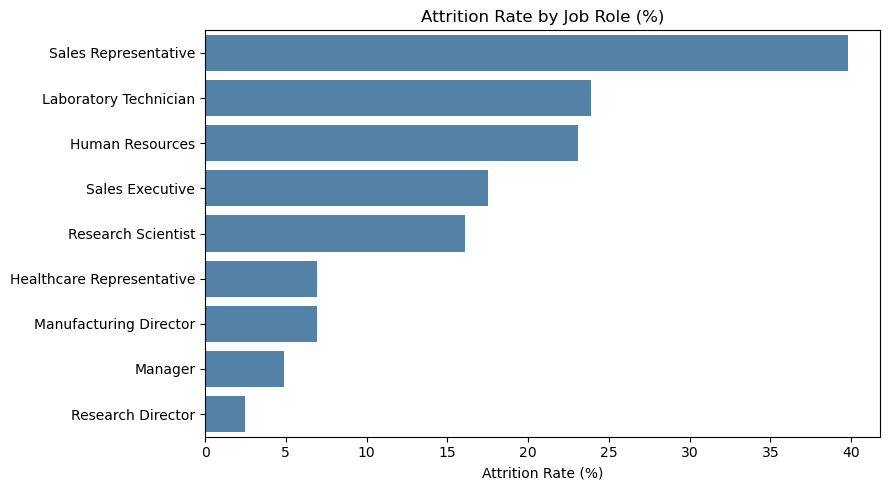

In [5]:
# Chart for job roles
plt.figure(figsize=(9, 5))
sns.barplot(data=role.sort_values("AttritionRate", ascending=False),
            x="AttritionRate", y="JobRole", color="steelblue")
plt.title("Attrition Rate by Job Role (%)")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [6]:
ot = df.groupby("OverTime")["AttritionFlag"].agg(["count", "sum", "mean"]).reset_index()
ot.columns = ["OverTime", "Employees", "Left", "AttritionRate"]
ot["AttritionRate"] = (ot["AttritionRate"] * 100).round(1)
ot

,OverTime,Employees,Left,AttritionRate
0,No,1054,110,10.4
1,Yes,416,127,30.5


In [7]:
inc = df.groupby("IncomeLevel", observed=True)["AttritionFlag"].agg(["count", "sum", "mean"]).reset_index()
inc.columns = ["IncomeLevel", "Employees", "Left", "AttritionRate"]
inc["AttritionRate"] = (inc["AttritionRate"] * 100).round(1)
inc

,IncomeLevel,Employees,Left,AttritionRate
0,High,275,33,12.0
1,Low,395,113,28.6
2,Medium,519,66,12.7
3,Very High,281,25,8.9


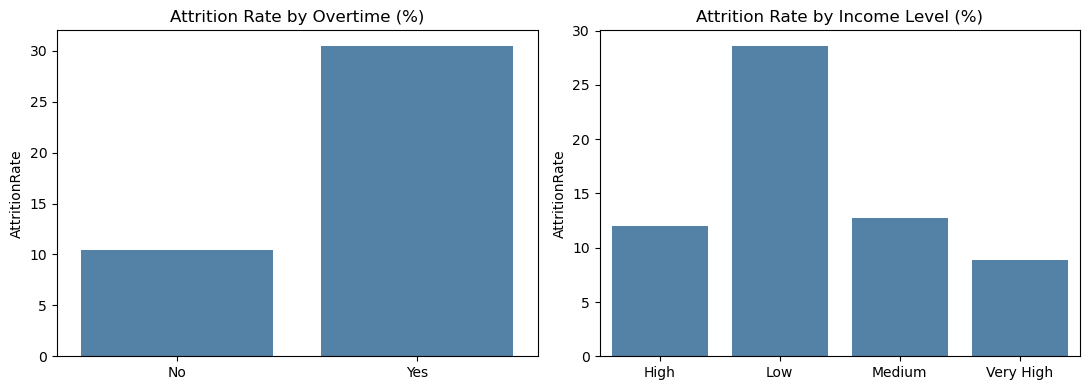

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=ot, x="OverTime", y="AttritionRate", color="steelblue", ax=axes[0])
axes[0].set_title("Attrition Rate by Overtime (%)")
axes[0].set_xlabel("")

sns.barplot(data=inc, x="IncomeLevel", y="AttritionRate", color="steelblue", ax=axes[1])
axes[1].set_title("Attrition Rate by Income Level (%)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

In [9]:
def attrition_by(col):
    t = df.groupby(col, observed=True)["AttritionFlag"].agg(["count", "sum", "mean"]).reset_index()
    t.columns = [col, "Employees", "Left", "AttritionRate"]
    t["AttritionRate"] = (t["AttritionRate"] * 100).round(1)
    return t

In [10]:
attrition_by("AgeGroup")

,AgeGroup,Employees,Left,AttritionRate
0,18-25,123,44,35.8
1,26-35,606,116,19.1
2,36-45,468,43,9.2
3,46-55,226,26,11.5
4,56+,47,8,17.0


In [11]:
attrition_by("TenureBand")

,TenureBand,Employees,Left,AttritionRate
0,0-2 yrs,342,102,29.8
1,11+ yrs,246,20,8.1
2,3-5 yrs,434,60,13.8
3,6-10 yrs,448,55,12.3


In [12]:
attrition_by("JobSatisfaction")

,JobSatisfaction,Employees,Left,AttritionRate
0,1,289,66,22.8
1,2,280,46,16.4
2,3,442,73,16.5
3,4,459,52,11.3


In [13]:
attrition_by("WorkLifeBalance")

,WorkLifeBalance,Employees,Left,AttritionRate
0,1,80,25,31.2
1,2,344,58,16.9
2,3,893,127,14.2
3,4,153,27,17.6


In [14]:
df.groupby("Attrition")[["JobSatisfaction", "WorkLifeBalance",
                         "YearsSinceLastPromotion", "MonthlyIncome",
                         "DistanceFromHome"]].mean().round(2)

,JobSatisfaction,WorkLifeBalance,YearsSinceLastPromotion,MonthlyIncome,DistanceFromHome
Attrition,,,,,
No,2.78,2.78,2.23,6832.74,8.92
Yes,2.47,2.66,1.95,4787.09,10.63


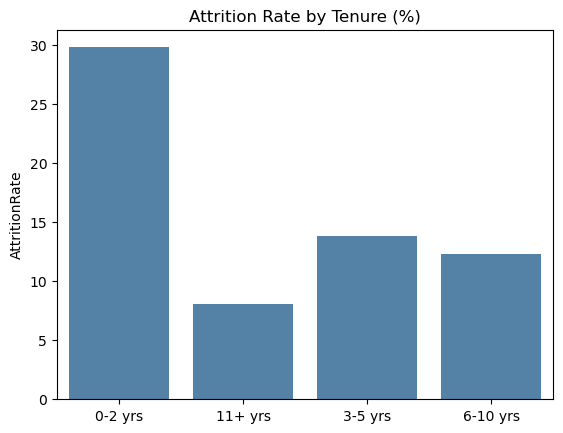

In [15]:
tenure = attrition_by("TenureBand")
sns.barplot(data=tenure, x="TenureBand", y="AttritionRate", color="steelblue")
plt.title("Attrition Rate by Tenure (%)")
plt.xlabel("")
plt.show()